# Планирование
>Этот раздел посвящен улучшению методов, **<font color='orange'>опирающихся на модель окружающей среды</font>** (model-based). Из известных сейчас нам методов - это **<font color='orange'>ДП и эвристический поиск</font>**. Из методов, допускающих **<font color='orange'>использование без модели</font>** (model-free), мы изучили **<font color='orange'> МК и TD</font>**. Методы на основе модели полагаются на **<font color='orange'>планирование</font>**, безмодельные методы – на **<font color='orange'>обучение</font>**.


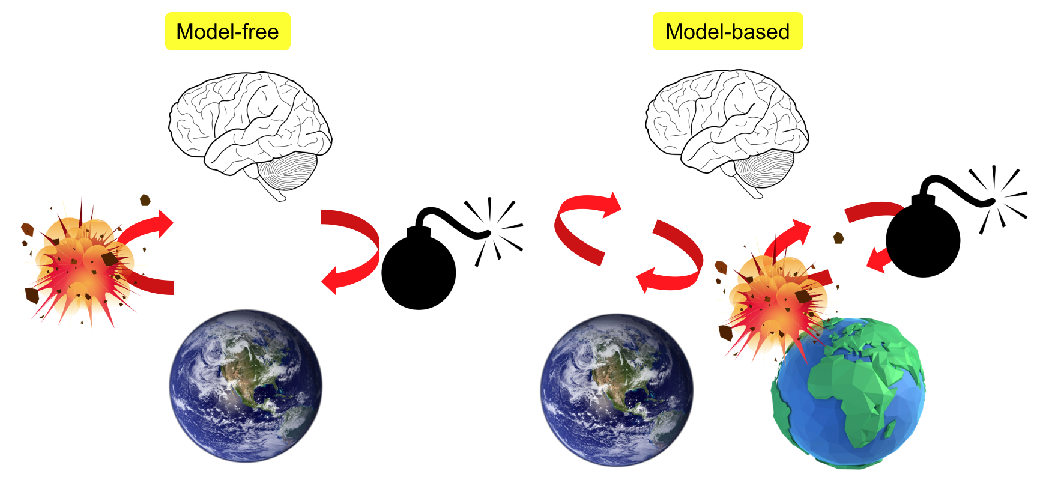

Между двумя видами методов model-based и model-free существуют как вполне осязаемые различия, так и общие черты. В частности, **<font color='orange'>те и другие базируются на вычислении функции ценности</font>**. Кроме того, все методы разделяют **<font color='orange'>общие принципы</font>**: заглядывание вперед для рассмотрения будущих событий, вычисление обновленной оценки события и последующее использование ее как цели обновления для аппроксимированной функции ценности.

При этом, если добавить модель в безмодельные методы, то можно их **<font color='orange'>улучшить и ускорить обучение</font>**.

## Модели и планирование
>**<font color='orange'>Модель окружающей среды</font>** - это то, что имитирует поведение среды или, в более общем смысле, позволяет делать выводы о том, как будет вести себя среда. Модели используются для **<font color='orange'>планирования</font>**, под которым мы подразумеваем любой способ принятия решения о курсе действий путем рассмотрения возможных будущих ситуаций до того, как они действительно возникнут. Методы без моделей же основаны на **<font color='orange'>методах проб и ошибок</font>** и рассматриваются как почти противоположные планированию.

Под моделью окружающей среды мы понимаем **<font color='orange'>всё, что агент может использовать для предсказания вероятной реакции среды на свои действия</font>**. Зная состояние и действие, модель порождает **<font color='orange'>предсказание следующего состояния и вознаграждения</font>**. Если модель стохастическая, то существует несколько возможных следующих состояний и вознаграждений, с каждым из которых связана **<font color='orange'>вероятность</font>**.

Некоторые модели порождают описание всех возможностей и их вероятностей; они называются **<font color='orange'>моделями распределения</font>**. Другие модели порождают только одну из возможностей, выбранную согласно вероятности; они называются **<font color='orange'>моделями выборки</font>**.

Например, в ДП (оценивании динамики МППР, $p(s', r | s, a)$) подразумевается **<font color='orange'>модель распределения</font>**. А в примере игры в блэкджек из методички о методах МК используется **<font color='orange'>модель выборки</font>**.

**<font color='orange'>Модели распределения более универсальны</font>**, чем модели выборки, поскольку их всегда можно использовать для **<font color='orange'>порождения выборки</font>**. Но в большинстве задач **<font color='orange'>гораздо проще получить модель выборки</font>**, чем модель распределения.

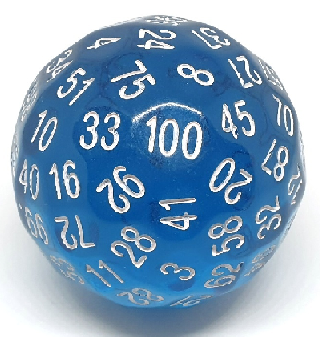

Например, бросок костей. Легко написать программу, которая моделирует бросок костей и возвращает выпавшую сумму, а вот перечислить все возможные суммы и их вероятности труднее и чревато ошибками.

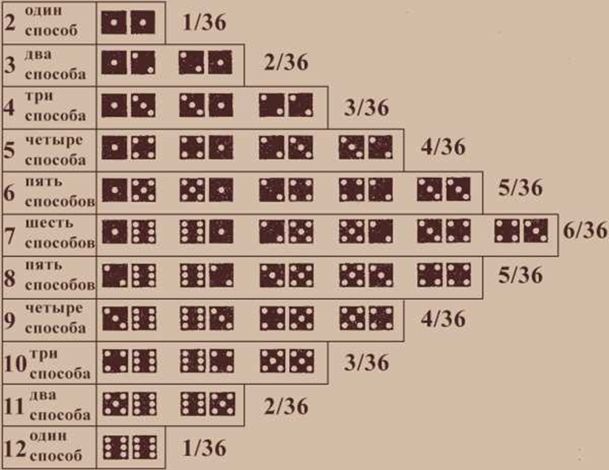

Модели можно использовать для **<font color='orange'>имитации опыта.</font>** Если известны начальное состояние и действие, то модель выборки порождает **<font color='orange'>возможный переход</font>**, а модель распределения генерирует **<font color='orange'>все возможные переходы, каждому из которых сопоставлен вес</font>**, определяемый его вероятностью. Если известны начальное состояние и стратегия, то модель выборки могла бы породить **<font color='orange'>весь эпизод</font>**, а модель распределения – **<font color='orange'>все возможные эпизоды и их вероятности</font>**. В любом случае мы говорим, что модель используется для **<font color='orange'>имитации окружающей среды и порождения имитированного опыта</font>**.

В области RL со стохастическими задачами последовательного принятия решений наиболее подходящим вариантом планирования является **<font color='orange'>планирование в пространстве состояний</font>**. Оно рассматривается в основном как **<font color='orange'>поиск оптимальной стратегии или оптимального пути к цели в пространстве состояний</font>**. В его базис входят две основные идеи: **<font color='orange'>(1)</font>** все методы планирования в пространстве состояний включают вычисление функций ценности в качестве ключевого промежуточного шага в направлении улучшения стратегии и **<font color='orange'>(2)</font>** они вычисляют функции ценности с помощью операций обновления, применяемого к имитированному опыту.

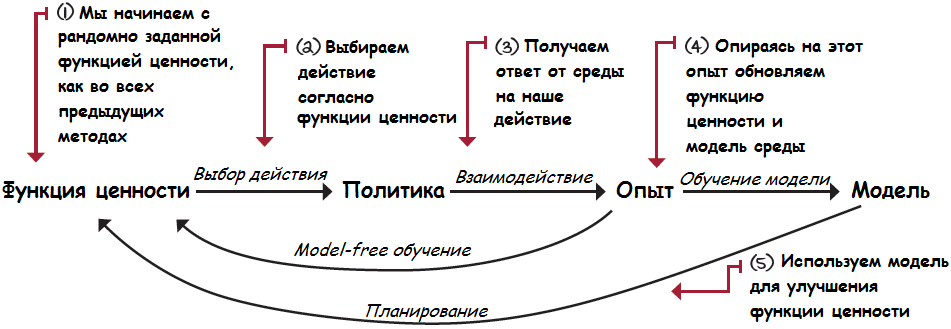

Очевидно, что **<font color='orange'>методы ДП обладают такой структурой</font>**: они выполняют проходы по пространству состояний, генерируя для каждого состояния распределение возможных переходов. Затем каждое распределение используется для вычисления цели обновления и новой оценки ценности состояния. И многие другие **<font color='orange'>методы планирования в пространстве состояний также обладают этой структурой</font>**, а различаются только **<font color='orange'>способами обновления, порядком их выполнения и сроками хранения информации</font>**, используемой для обновления.


Такой взгляд на методы планирования подчеркивает их **<font color='orange'>связь с методами обучения</font>**. В основе методов обучения и планирования лежит **<font color='orange'>вычисление функций ценности с помощью операции обновления</font>**. А различие между ними заключается в том, что **<font color='orange'>при планировании используется имитированный опыт</font>**, генерируемый **<font color='orange'>моделью</font>**, а **<font color='orange'>при обучении используется реальный опыт</font>**, генерируемый **<font color='orange'>окружающей средой</font>**.

Но наличие общей структуры означает, что **<font color='orange'>многие идеи и алгоритмы переносятся с планирования на обучение и наоборот</font>**. В частности, во многих случаях вместо ключевого шага обновления в методе планирования можно подставить алгоритм обучения. На вход методов обучения необходимо подавать только опыт, и во многих случаях этот опыт может быть как реальным, так и имитированным.

Во врезке ниже приведен пример **<font color='orange'>простого метода планирования, основанного на одношаговом табличном Q-обучении и случайных выборках из модели выборки</font>**. Этот метод сходится к оптимальной стратегии для модели при тех же условиях, при которых одношаговое табличное Q-обучение сходится к оптимальной стратегии для реальной окружающей среды (естественно, каждая пара состояние–действие должна выбираться бесконечное число раз на шаге 1, и параметр $α$ должен соответствующим образом убывать с течением времени).



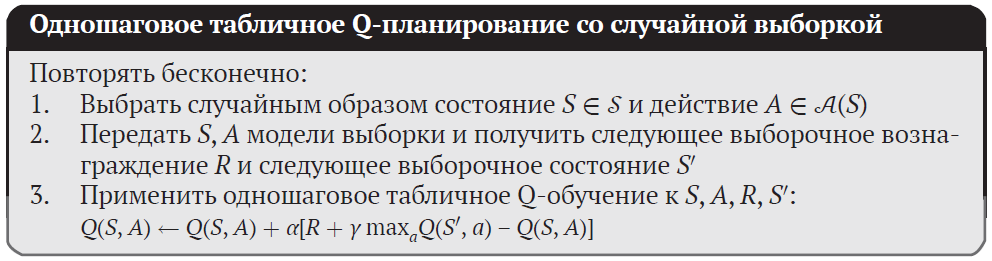

Кроме этого, еще один важный момент. **<font color='orange'>Планирование очень мелкими шагами может оказаться наиболее эффективным подходом даже при решении задачи чистого планирования, если она слишком велика для точного решения</font>**. Это позволяет прерывать планирование или изменять его направление в любой момент с небольшими потерями на лишние вычисления, что является ключевым требованием к эффективному сочетанию планирования с взаимодействием (исполнением) и с обучением модели.

## Dyna: объединение планирования, взаимодействия (исполнения) и обучения
>Если планирование производится в **<font color='orange'>онлайновом режиме</font>**, в процессе взаимодействия с окружающей средой (параллельно), то возникает ряд интересных вопросов. Новая информация, получаемая в ходе взаимодействия, может изменять модель и, значит, **<font color='orange'>взаимодействовать с планированием</font>**. Иногда желательно тем или иным способом подстраивать процесс планирования к состояниям или решениям, анализируемым в  данный момент или ожидаемым в ближайшем будущем. Если процессы принятия решений и обучения модели требуют большого объема вычислений, то вычислительные ресурсы, возможно, придется разделить между ними.

In [ ]:
from IPython.display import Image
Image(url='https://assets-global.website-files.com/621e749a546b7592125f38ed/62271e2f604e640534eeca99_AlphaStar%2003.gif')

Как мы уже обсудили выше, основное преимущество безмодельных методов перед методами планирования заключается в том, что первые **<font color='orange'>не требуют модель окружающей среды</font>**. **<font color='orange'>Часто модели сложно получить заранее, а иногда даже невозможно</font>**. Представьте себе игру Го с $10^{170}$ возможными состояниями или StarCraft II с $10^{1685}$ состояниями. Это значащие числа, и они еще даже не включают функции переходов.

Но давайте задумаемся на секунду: **<font color='orange'>что, если нам не требуется заранее знать модель</font>**, но, возможно, мы **<font color='orange'>получим ее, взаимодействуя с реальной окружающей средой</font>**? Например, когда мы гуляем по новым местам, начинаем строить подобие карты в своей голове. Спустя какое-то время, находим кофейню, покупаем кофе и при этом знаем, как вернуться обратно к началу нашего маршрута.

В этом разделе мы разберем **<font color='orange'>архитектуру агента онлайнового обучения Dyna-Q</font>**, который взаимодействует с реальной средой, при этом обладает возможностью изучения модели среды, полученной из этих взаимодействий.

Внутри агента планирования у реального опыта есть по меньшей мере две функции: он может использоваться для **<font color='orange'>улучшения модели</font>** (чтобы она более точно отражала реальную окружающую среду) и для непосредственного **<font color='orange'>улучшения функции ценности и стратегии</font>** с применением тех методов обучения с подкреплением, которые мы обсуждали до этого. Первое называется **<font color='orange'>обучением модели</font>**, второе – **<font color='orange'>прямым обучением с подкреплением</font>** (прямым ОП, прямым RL).

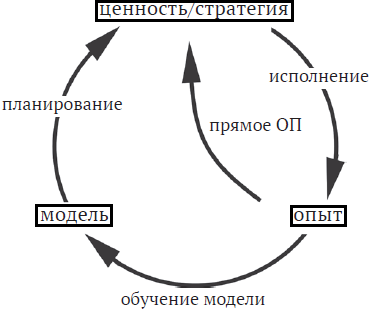

Обратите внимание, что на рисунке выше **<font color='orange'>опыт может улучшить функции ценности и стратегии как непосредственно, так и опосредованно с помощью модели</font>**. Последнее, иногда называемое **<font color='orange'>косвенным обучением с подкреплением</font>**, является составной частью планирования.

У прямых и косвенных методов есть свои достоинства и недостатки. Косвенные методы зачастую **<font color='orange'>более полно используют ограниченный объем опыта</font>** и потому достигают лучшей стратегии при меньшем взаимодействии с окружающей средой. С другой стороны, прямые методы гораздо **<font color='orange'>проще и не подвержены влиянию искажений</font>**, появляющихся при проектировании модели. Исследователи до сих пор не пришли к единому мнению, что лучше.

Dyna-Q включает в себя все процессы, показанные на рисунке выше, причем все они протекают **<font color='orange'>непрерывно</font>**. В этом алгоритме **<font color='orange'>метод планирования</font>** представляет собой **<font color='orange'>одношаговый табличный метод Q-планирования</font>**, описанный в предыдущем разделе. А **<font color='orange'>метод прямого обучения</font>** – это **<font color='orange'>одношаговое табличное Q-обучение</font>**. Метод обучения модели также **<font color='orange'>табличный</font>** и предполагает, что окружающая среда **<font color='orange'>детерминирована</font>**. После каждого перехода $S_t, A_t ⟶ R_{t+1}, S_{t+1}$ модель запоминает в элементе таблицы, соответствующем паре $S_t, A_t$, предсказание о том, что за ним детерминированно следует пара $R_{t+1}, S_{t+1}$. Таким образом, если модель получает запрос о паре $(S_t,A_t)$, которая уже наблюдалась ранее, то она просто возвращает в качестве предсказания последнее наблюдавшееся следующее состояние и следующее вознаграждение $R_{t+1}, S_{t+1}$. **<font color='orange'>Во время планирования</font>** алгоритм Q-планирования производит **<font color='orange'>случайные выборки только из пар $(s,a)$, которые наблюдались ранее</font>** (на шаге 1), поэтому модель **<font color='orange'>никогда</font>** не получает запросов о парах, для которых у нее нет информации. Это чем-то напоминает пакетироанный опыт, когда у нас было ограниченное количество переходов, на основе которого делались предсазания и обновления в методичке с TD.

Ниже показана **<font color='orange'>общая архитектура агентов Dyna и подобных ему</font>**. Термин **<font color='orange'>управление поиском</font>** применяется для обозначения процесса, который **<font color='orange'>выбирает начальные состояния и действия для имитированного опыта</font>**, сгенерированного моделью. Как правило, в т.ч. в Dyna-Q, **<font color='orange'>один и тот же метод обучения с подкреплением</font>** применяется как для обучения на реальном опыте, так и для планирования на основе имитированного опыта на базе модели. Поэтому метод обучения с подкреплением является «общим инструментом» обучения и планирования. Обучение и планирование глубоко **<font color='orange'>интегрированы</font>** в том смысле, что **<font color='orange'>пользуются практически одними и теми же механизмами</font>**, а **<font color='orange'>различаются только источником получения опыта</font>**.

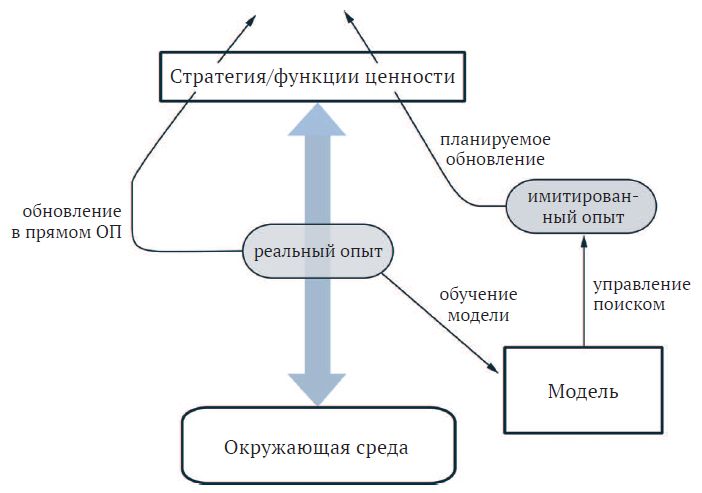


Концептуально планирование, исполнение, обучение модели и прямое RL происходят в Dyna-агентах **<font color='orange'>одновременно и параллельно</font>**. Но, чтобы иметь возможность реализовать эти процессы на **<font color='orange'>последовательном</font>** компьютере, мы должны точно **<font color='orange'>определить их порядок в течение одного временного шага</font>**.

В Dyna-Q процессы исполнения, обучения модели и прямого RL требуют небольшого объема вычислений, поэтому предполагается, что они занимают небольшую долю времени. **<font color='orange'>Оставшееся время на каждом шаге может быть потрачено на процесс планирования</font>**, который выполняет много вычислений.

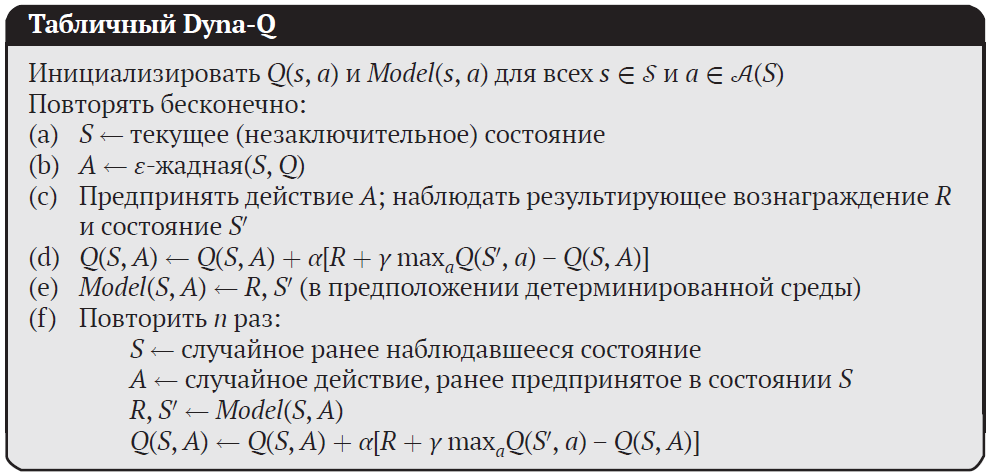

$Model(s, a)$ - **<font color='orange'>содержание модели</font>** (предсказанное следующее $s'$ и $r$) **<font color='orange'>для пары состояние–действие</font>** $(s, a)$. Прямое обучение с подкреплением, обучение модели и планирование реализованы в шагах **<font color='orange'>(d), (e) и (f)</font>** соответственно. Если опустить шаги (e) и (f), то получится алгоритм одношагового табличного Q-обучения.

#### Пример №1. Лабиринт с Dyna.

Рассмотрим простой лабиринт из **<font color='orange'>48 состояний с четырьмя действиями</font>**: up, down, right, left. Если перемещению мешает препятствие (квадраты закрашены серым цветом) или граница лабиринта, **<font color='orange'>агент остается на месте</font>**. **<font color='orange'>Вознаграждение равно 0</font>** за любое перемещение, **<font color='orange'>кроме тех, которые ведут в целевое состояние</font>**, а в этом случае **<font color='orange'>вознаграждение равно +1</font>**. Достигнув целевого состояния **<font color='orange'>(G)</font>**, агент возвращается в начальное состояние **<font color='orange'>(S)</font>**, и начинается новый эпизод. При этом коэффициент обесценивания **<font color='orange'>$γ = 0.95$</font>**.

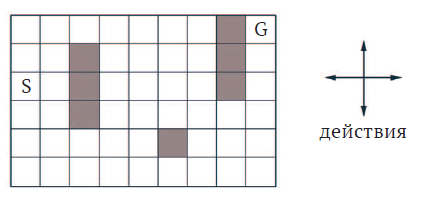

Ниже приведены **<font color='orange'>усредненные кривые обучения</font>**, полученные в эксперименте, в котором агенты Dyna-Q применялись к решению задачи о лабиринте. **<font color='orange'>Начальные ценности действий были равны нулю</font>**, **<font color='orange'>размер шага $α = 0.1$</font>**, а **<font color='orange'>параметр исследования $ε = 0.1$</font>**. При жадном выборе действий неоднозначности разрешались **<font color='orange'>случайным образом</font>**.

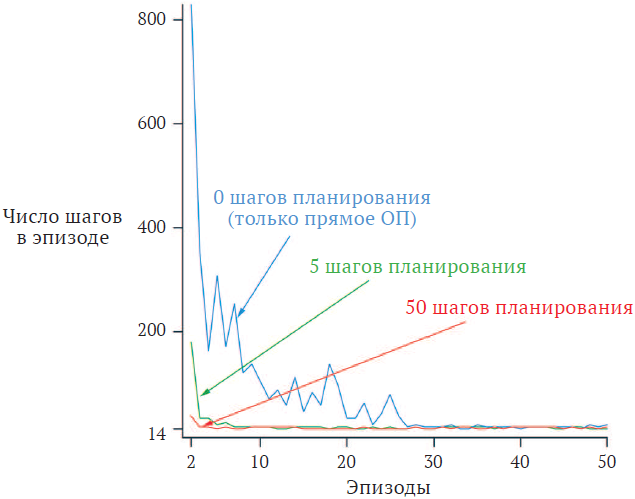

Агенты различались **<font color='orange'>по количеству шагов планирования $n$</font>**, совершаемых на **<font color='orange'>одном реальном шаге</font>**. Для каждого $n$ кривые показывают **<font color='orange'>число шагов</font>**, совершенных агентом для достижения цели в каждом эпизоде, **<font color='orange'>усредненное по $30$ повторениям эксперимента</font>**. Агенты различались **<font color='orange'>по количеству шагов планирования $n$</font>**, совершаемых на **<font color='orange'>одном реальном шаге</font>**. Для каждого $n$ кривые показывают **<font color='orange'>число шагов</font>**, совершенных агентом для достижения цели в каждом эпизоде, **<font color='orange'>усредненное по $30$ повторениям эксперимента</font>**.

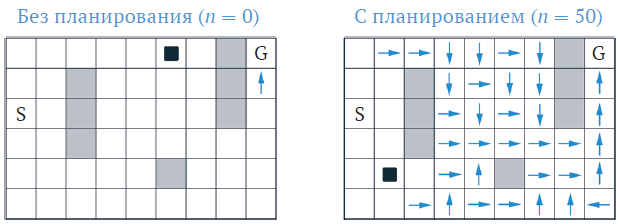

После первого эпизода результаты улучшаются для всех значений $n$, но особенно быстро для больших. В этой задаче **<font color='orange'>агент c $n = 0$ </font>**(агент ничего не планирует) **<font color='orange'>является самым медленным</font>**, несмотря на то что параметры ($α$ и $ε$) были выбраны для него оптимально. Без планирования ($n = 0$ на рисунке) каждый эпизод добавляет к стратегии лишь один дополнительный шаг, и, следовательно, **<font color='orange'>агент обучался только одному (последнему) шагу</font>**. При наличии планирования (**<font color='orange'>$n = 50$</font>** на рисунке) **<font color='orange'>в первом эпизоде агент также обучался только одному шагу</font>**, но **<font color='orange'>во втором эпизоде была выработана более сложная стратегия</font>**, которая к концу эпизода почти достигнет начального состояния.

#### Код для примера №1.

In [ ]:
import numpy as np
from numpy import random
from pandas import DataFrame

import itertools
import matplotlib.pyplot as plt
%matplotlib inline

from tqdm import autonotebook as tqdm

/tmp/ipykernel_928/3282833829.py:9: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm import autonotebook as tqdm


In [ ]:
# Инициализируем лабиринт из примера
# y
# ^
# |
# |
#-|------> x

# (x,y)
Start = (0,3) # Для примера №1.
Terminal = (8,5)
gamma = 0.95
alpha = 0.1
eps = 0.1

actions = [(-1,0), (1,0), (0,-1), (0,1)]

# Для примера №1
walls_1 = [(2, 2), (2, 3), (2, 4), (5, 1), (7, 3), (7, 4), (7, 5)]

In [ ]:
def choose_act(Q, s):
  if (np.random.sample() > eps):
    a = get_optimal(Q, s)
  else:
    a = np.random.randint(0, 4)
  return a

def get_optimal(Q, s):
  j = Q[s]
  if all(b==j[0] for b in j):
    a = np.random.randint(0, 4)
  else:
    a = np.argmax(j)
  return a

def next_state(s, a, count):
  x = s[0] + actions[a][0]
  y = s[1] + actions[a][1]

  # Если вышли за границы лабиринта, возвращаем агента на предыдущее место
  if (y < 0 or y > 5):
    x = s[0]
    y = s[1]
  if (x < 0 or x > 8):
    x = s[0]
    y = s[1]

  # Для примера №1
  walls_stox = walls_1

  # Если агент натыкается на стену, возвращаем его на предыдущий шаг
  if ((x,y) in walls_stox):
    x = s[0]
    y = s[1]

  r = 0
  if ((x,y) == Terminal): # Награда дается только за достижене цели
    r = 1

  return (x, y), r

In [ ]:
def Dyna_Q(episodes, n):
  Q = np.zeros((9, 6, 4)) # Табличка под оценки четрех действий в каждом состоянии лабиринта 9*6*4 = 216
  Model = np.empty([9, 6, 4], tuple) # Здесь tuple, так как сохраняем награду и следующее состояние: см. (e)

  count_steps = [] # Записываем, на каком общем шаге каждый эпизод закончился (все шаги во всех эпизодах считаются вместе)
  visited_states = set()  # Записываем, какие пары (s,a) посетили для модели

  s = Start

  for i in range(episodes):
    count = 0 # Считаем, сколько шагов сделали всего по всем эпизодам, т.к. в примерах №2 и №3 в зависимости от этого меняется лабиринт
    s = Start
    while (s != Terminal):
      count += 1
      a = choose_act(Q, s)
      visited_states.add((s, a))

      s_next, r = next_state(s, a, count)

      # Прямое ОП
      max_Q = 0 if s_next == Terminal else np.max(Q[s_next])
      Q[s[0], s[1], a] += alpha*(r + gamma*max_Q - Q[s[0], s[1], a])

      # Обучение модели
      Model[s[0], s[1], a] = (r, s_next)
      states_list = list(visited_states)

      # Планирование
      for k in range(n):
        idx = np.random.choice(len(states_list))
        s_plan, a_plan = states_list[idx]
        r_plan, s_next_plan = Model[s_plan[0], s_plan[1], a_plan]
        max_Q = 0 if s_next_plan == Terminal else np.max(Q[s_next_plan])
        Q[s_plan[0], s_plan[1], a_plan] += alpha*(r_plan + gamma*max_Q - Q[s_plan[0], s_plan[1], a_plan])

      s = s_next

    count_steps.append(count)

  return count_steps

  0%|          | 0/2 [00:00<?, ?it/s]

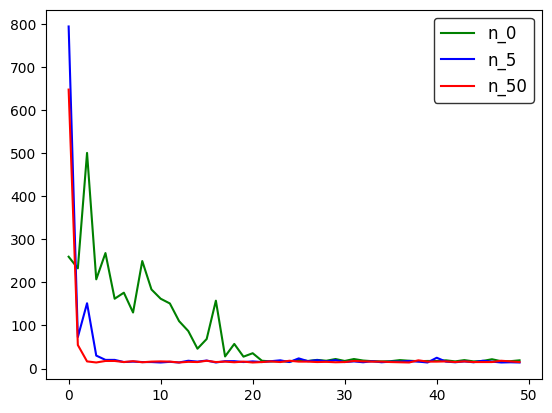

In [ ]:
# Пример №1
num_try = 2
count_steps_0 = []
count_steps_5 = []
count_steps_50 = []

for q in tqdm.trange(num_try):
  count_steps_0.append(Dyna_Q(50, 0))
  count_steps_5.append(Dyna_Q(50, 5))
  count_steps_50.append(Dyna_Q(50, 50))

count_steps_0_mean = np.mean(count_steps_0, axis=0)
count_steps_5_mean = np.mean(count_steps_5, axis=0)
count_steps_50_mean = np.mean(count_steps_50, axis=0)

x = np.arange(0, 50, 1)
plt.plot(x, count_steps_0_mean, "g", label='n_0')
plt.plot(x, count_steps_5_mean, "b", label='n_5')
plt.plot(x, count_steps_50_mean, "r", label='n_50')
plt.legend(fontsize=12, edgecolor='black')

В Dyna-Q обучение и планирование реализованы **<font color='orange'>одним и тем же алгоритмом</font>**, который использует **<font color='orange'>реальный опыт для обучения</font>** и **<font color='orange'>имитированный для планирования</font>**. Поскольку планирование производится **<font color='orange'>пошагово</font>**, чередовать планирование и исполнение очень просто (см. в этом разделе первую диаграмму). Не смотря на изменения поведения и модели, а также реакцию агента на них, он **<font color='orange'>постоянно продолжает планирование и обучение модели</font>** в фоновом режиме.

#### Обсуждение 1


1. В примере выше непланирующий метод выглядит особенно плохо, поскольку является одношаговым; метод с многошаговым бутстрэппингом работал бы лучше. Проверьте программно, может ли один из методов с многошаговым бутстрэппингом, рассмотренных в прошлой методичке, показать такие же хорошие результаты, как метод Dyna?

#### Подсказки 1

1.   Теоретически - для данной задачи вряд ли такой найдется. У нас все равно есть ограничение на количество шагов бутстеппинга $n$. У планирования такого ограничения нет (хоть в длинну всего эпизода, если хватает времени - в данном случае за время отвечает также количество шагов). Плюс, если у n-шагового алгоритма $Q_t(S_{t+n},A_{t+n}) = 0$, то обновления нет. А вообще в других задачах может и оказаться лучше, но тут вопрос в ресурсоемкости. Планирование все же меньше занимает и быстрее отрабатывает.

## Когда модель неверна
>В большинстве случаев при обучении **<font color='orange'>модель скорее всего будет неверна</font>** либо из-за того, что **<font color='orange'>окружающая среда стохастическая, и наблюдалось лишь ограниченное количество примеров</font>**, либо из-за того, что **<font color='orange'>при обучении модели использовалась приближенная функция</font>**, которая плохо обобщается, либо просто из-за того, что **<font color='orange'>среда изменилась и ее новое поведение еще не изучено</font>**. Если модель неправильна, то **<font color='orange'>процесс планирования</font>**, скорее всего, **<font color='orange'>будет вычислять неоптимальную стратегию</font>**.

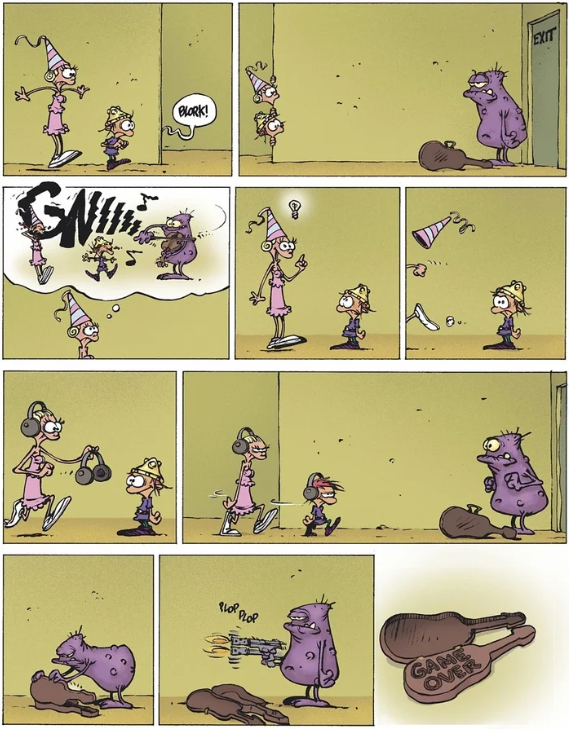

В некоторых случаях вычисленная процессом планирования **<font color='orange'>неоптимальная стратегия</font>** быстро приводит к **<font color='orange'>обнаружению и исправлению ошибок моделирования</font>**. Обычно это происходит, когда **<font color='orange'>модель оптимистичная</font>** в том смысле, что предсказывается большее вознаграждение или лучшие переходы состояний, чем возможно на самом деле.

#### Пример №2. Изменяющийся лабиринт.

В этом примере лабиринт будет **<font color='orange'>изменятся после достижения суммы в $1000$ временных шагов</font>**. Изначально существует короткий путь от старта к цели справа от барьера, потом короткий путь оказывается «заблокированным», но открывается более длинный путь слева от барьера. На графике показано **<font color='orange'>среднее накопленное вознаграждение</font>** для агента **<font color='orange'>Dyna-Q</font>** и улучшенного агента **<font color='orange'>Dyna-Q+</font>**.

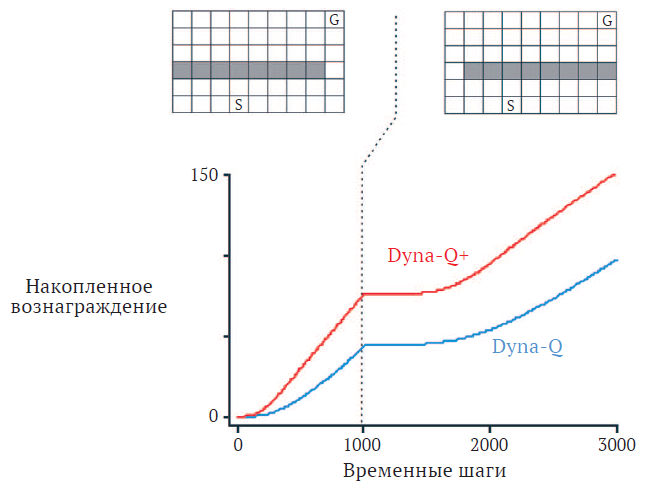

Из первой части графика видно, что **<font color='orange'>оба Dyna-агента нашли короткий путь за 1000 шагов</font>**. Когда окружающая среда **<font color='orange'>изменилась</font>**, на графиках появилось **<font color='orange'>горизонтальное плато</font>**, соответствующее периоду, в течение которого агенты не получали никакого вознаграждения, потому что находились за барьером. Cпустя некоторое время они **<font color='orange'>сумели найти новый проход и новую оптимальную линию поведения</font>**. Но улучшенный Dyna-Q+ справился лучше.

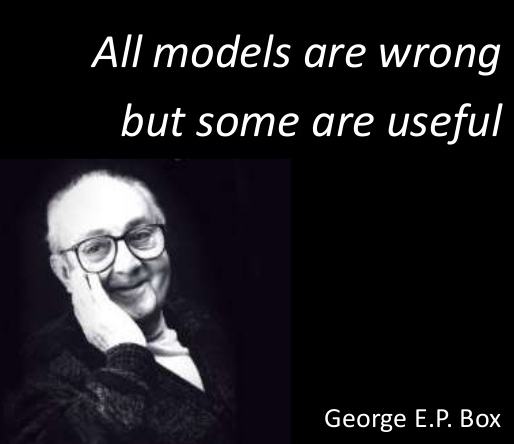

#### Пример №3. Короткий путь в лабиринте.

Более серьезные трудности возникают, когда в процессе изменения **<font color='orange'>окружающая среда становится лучше, чем прежде</font>**, но выработанная ранее правильная стратегия **<font color='orange'>не замечает этих улучшений</font>**. В такой ситуации ошибка моделирования может быть обнаружена спустя длительное время, а то и вовсе не обнаруживается.

В данном изменяющемся лабиринте **<font color='orange'>после 3000 шагов открывается более короткий путь справа от барьера</font>**, при этом длинный путь тоже остается открытым. Из графика видно, что **<font color='orange'>обычный агент Dyna-Q даже не понял, что появился более короткий путь</font>**. Его модель довольно долгое время сообщала, что нет никакого короткого пути, поэтому чем дольше он планировал, тем меньше становилась вероятность сделать шаг вправо и обнаружить этот путь.

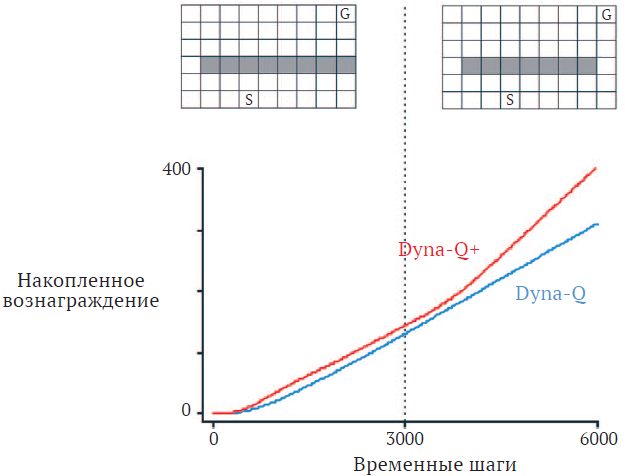

**<font color='orange'>Даже при $ε$-жадной стратегии крайне маловероятно, что агент будет предпринимать так много исследовательских действий</font>**, что обнаружит короткий путь. В данном случае общая проблема заключается еще в одном **<font color='orange'>варианте конфликта между исследованием и использованием</font>**, только теперь **<font color='orange'>для планирования</font>**. В этом случае **<font color='orange'>исследование</font>** означает, что нужно пытаться выбирать действия, улучшающие модель, а **<font color='orange'>использование</font>** – что нужно выбирать оптимальную линию поведения в рамках текущей модели.

Один из вариантов решения такой проблемы как раз используется в **<font color='orange'>Dyna-Q+</font>**. Это применение **<font color='orange'>простых эвристик</font>**. Для каждой пары состояние–действие этот агент запоминает, **<font color='orange'>сколько временных шагов прошло с момента последнего опробования этой пары в реальном взаимодействии со средой</font>**. Чем больше прошло времени, тем больше (предположительно) шансов, что **<font color='orange'>динамика этой пары изменилась и ее модель уже неверна</font>**. Чтобы побудить агента совершать давно не проверявшиеся действия, назначается специальное «**<font color='orange'>бонусное вознаграждение</font>**» за имитированный опыт, приводящий к таким действиям.

Всего в Dyna-Q+ внесено **<font color='orange'>3 изменения</font>**, остальное копирует поведение Dyna-Q:

1.   **<font color='orange'>Эвристика</font>**: если смоделированное вознаграждение за переход равно $R$ и этот переход не выполнялся в течение $τ$ временных шагов, то производится обновление планирования, как если бы за данный переход полагалось вознаграждение $R + κ\sqrtτ$ при некотором небольшом значении $κ$.
2.   Действия, которые **<font color='orange'>раньше никогда не проверялись в некотором состоянии, разрешено рассматривать на шаге планирования (f)</font>**.
3.   **<font color='orange'>Начальная модель таких действий</font>** из пункта 2 подразумевает, что они должны осуществлять **<font color='orange'>переход в то же самое состояние с нулевым вознаграждением</font>**.

И хотя эти проверки имеют свою цену, но **<font color='orange'>во многих ситуациях</font>**, в т.ч. в задаче о коротком пути в лабиринте, такое «любопытство» к дополнительному исследованию вполной мере **<font color='orange'>окупается</font>**.



При поиске в интернете можно найти минимум три варианта интерпретации Dyna-Q+. Эти интерпретации связаны с трактовкой 2 и 3 изменений. В курсе мы будет опираться на описание алгоритма от Ричарда Саттона и Эндрю Барто.

>По второму варианту, предлагаемому в интернете, предлагается рассматривать в планировании не только любые возможные действия (даже не проверенные), но и также любые возможные состояния. И переход при моделировании также осуществляется в то же самое состояние с нулевым вознаграждением. Т.е. в (f) будут строки: \
>>$S ⟵$ случайное состояние из возможных в среде \
>>$A ⟵$ случайное ддействие из возможных в состоянии $S$

>По третьему варианту можно не найти упоминания о таких изменениях в алгоритме, только изменение 1 с дополнительной наградой.


#### Код для примеров №2,3.

In [ ]:
import numpy as np
from numpy import random
from pandas import DataFrame

import itertools
import matplotlib.pyplot as plt
%matplotlib inline

from tqdm import autonotebook as tqdm

In [ ]:
# Инициализируем лабиринт из примера
# y
# ^
# |
# |
#-|------> x

# (x,y)
Start = (3,0) # Для примера №2,3.
Terminal = (8,5)
gamma = 0.95
alpha = 0.1
eps = 0.1

actions = [(-1,0), (1,0), (0,-1), (0,1)]

# Для примера №2
wall_close_2 = [(1, 2), (2, 2), (3, 2), (4, 2), (5, 2), (6, 2), (7, 2), (8, 2)] # Закрыт короткий путь
wall_open_2 =  [(0, 2), (1, 2), (2, 2), (3, 2), (4, 2), (5, 2), (6, 2), (7, 2)] # Открыт короткий путь

# Для примера №3
wall_close_3 = [(1, 2), (2, 2), (3, 2), (4, 2), (5, 2), (6, 2), (7, 2), (8, 2)]  # Открыт длинный путь
wall_open_3 =  [(1, 2), (2, 2), (3, 2), (4, 2), (5, 2), (6, 2), (7, 2)] # Открыты оба пути

In [ ]:
def choose_act(Q, s):
  if (np.random.sample() > eps):
    a = get_optimal(Q, s)
  else:
    a = np.random.randint(0, 4)
  return a

def get_optimal(Q, s):
  j = Q[s]
  if all(b==j[0] for b in j):
    a = np.random.randint(0, 4)
  else:
    a = np.argmax(j)
  return a

def next_state(s, a, count):
  x = s[0] + actions[a][0]
  y = s[1] + actions[a][1]

  # Если вышли за границы лабиринта, возвращаем агента на предыдущее место
  if (y < 0 or y > 5):
    x = s[0]
    y = s[1]
  if (x < 0 or x > 8):
    x = s[0]
    y = s[1]

  # Для примера №2
  walls_stox = wall_open_2
  if (count >= 1000):
    walls_stox = wall_close_2 # Закрываем короткий путь, открываем длинный

  # Для примера №3
  #walls_stox = wall_close_3
  #if (count >= 3000):
  #  walls_stox = wall_open_3 # Открываем второй (короткий) путь

  # Если агент натыкается на стену, возвращаем его на предыдущий шаг
  if ((x,y) in walls_stox):
    x = s[0]
    y = s[1]

  r = 0
  if ((x,y) == Terminal): # Награда дается только за достижене цели
    r = 1

  return (x, y), r

In [ ]:
def Dyna_Q(n):
  Q = np.zeros((9, 6, 4)) # Табличка под оценки четрех действий в каждом состоянии лабиринта 9*6*4 = 216
  Model = np.empty([9, 6, 4], tuple) # Здесь tuple, так как сохраняем награду и следующее состояние: см. (e)

  count_steps = []
  rewards = []
  visited_states = set()

  s = Start
  count = 1
  reward = 0

  while (count <= 3000): # Для примера №3 6000 шагов
    a = choose_act(Q, s)
    visited_states.add((s, a)) # Запоминаем, что в этом состоянии мы были

    s_next, r = next_state(s, a, count)
    reward += r
    rewards.append(reward)

    # Прямое обучение
    max_Q = 0 if s_next == Terminal else np.max(Q[s_next])
    Q[s[0], s[1], a] += alpha * (r + gamma * max_Q - Q[s[0], s[1], a])

    # Обучение модели
    Model[s[0], s[1], a] = (r, s_next)

    if s_next == Terminal:
      s_next = Start

    states_list = list(visited_states)

    # Планирование
    for k in range(n):
      idx = np.random.choice(len(states_list))
      s_plan, a_plan = states_list[idx]

      r_plan, s_next_plan = Model[s_plan[0], s_plan[1], a_plan]

      max_Q_plan = 0 if s_next_plan == Terminal else np.max(Q[s_next_plan])
      Q[s_plan[0], s_plan[1], a_plan] += alpha * (r_plan + gamma * max_Q_plan - Q[s_plan[0], s_plan[1], a_plan])

    s = s_next
    count_steps.append(count)
    count += 1

  return rewards


In [ ]:
def Dyna_Q_p(n):
  Q = np.zeros((9, 6, 4)) # Табличка под оценки четрех действий в каждом состоянии лабиринта 9*6*4 = 216
  Model = np.empty((9, 6, 4), tuple) # Здесь tuple, так как сохраняем награду и следующее состояние: см. (e)
  for x in range(9):
    for y in range(6):
      for a in range(4):
        Model[x, y, a] = (0, (x, y), 0) # Предзаполняем для планирования

  count_steps = []
  rewards = []
  # Храним только уникальные когда-либо посещенные состояния
  visited_states = set()

  s = Start
  count = 1
  reward = 0
  while (count <= 3000): # Для примера №3 6000 шагов
    a = choose_act(Q, s)
    visited_states.add((s, a)) # Запоминаем, что эту пару видели

    s_next, r = next_state(s, a, count)
    reward += r
    rewards.append(reward)

    # Прямое обучение
    max_Q = 0 if s_next == Terminal else np.max(Q[s_next])
    Q[s[0], s[1], a] += alpha * (r + gamma * max_Q - Q[s[0], s[1], a])

    # Обучение модели, записываем шаг, на котором предприняли (s,a)
    Model[s[0], s[1], a] = (r, s_next, count)

    if s_next == Terminal:
      s_next = Start

    states_list = list(visited_states)

    # Планирование
    for k in range(n):
      # Нужно скорректировать планирование для Dyna-Q+
      idx = np.random.choice(len(states_list))
      s_plan, a_plan = states_list[idx]

      r_plan, s_next_plan, step = Model[s_plan[0], s_plan[1], a_plan]

      # Не забываем про бонусное вознаграждение
      add = 0.001 # Небольшой коэффициент
      r_plan += add * np.sqrt(count - step)

      max_Q_plan = 0 if s_next_plan == Terminal else np.max(Q[s_next_plan])
      Q[s_plan[0], s_plan[1], a_plan] += alpha * (r_plan + gamma * max_Q_plan - Q[s_plan[0], s_plan[1], a_plan])

    s = s_next
    count_steps.append(count)
    count += 1

  return rewards

In [ ]:
# Пример №2
num_try = 30
rewards_50 = []
rewards_50_p = []

for q in tqdm.trange(num_try):
  rewards_50.append(Dyna_Q(50))
  rewards_50_p.append(Dyna_Q_p(50))

rewards_50_mean = np.mean(rewards_50, axis=0)
rewards_50_p_mean = np.mean(rewards_50_p, axis=0)

x = np.arange(0, 3000, 1)
plt.plot(x, rewards_50_mean, "r", label='n_50')
plt.plot(x, rewards_50_p_mean, "k", label='n_50')
plt.legend(fontsize=12, edgecolor='black')

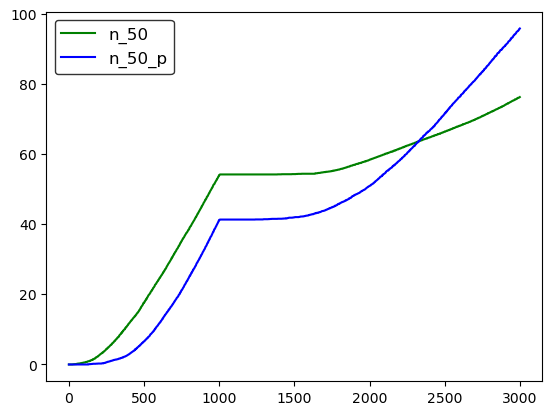

In [ ]:
# Пример №3
num_try = 30
rewards_50 = []
rewards_50_p = []

for q in tqdm.trange(num_try):
  rewards_50.append(Dyna_Q(50))
  rewards_50_p.append(Dyna_Q_p(50))

rewards_50_mean = np.mean(rewards_50, axis=0)
rewards_50_p_mean = np.mean(rewards_50_p, axis=0)

x = np.arange(0, 6000, 1)
plt.plot(x, rewards_50_mean, "r", label='n_50')
plt.plot(x, rewards_50_p_mean, "k", label='n_50')
plt.legend(fontsize=12, edgecolor='black')

#### Обсуждение 2

Указание для заданий 1-3 текущего обсуждения: используйте модифицированный код к примерам №2-3, напишите на базе Dyna-Q улучшенный Dyna-Q+ и постройте необходимые графики (не забудьте к гарфикам из примера №2-3). Не забывайте менять среду - в каждом примере меняется начальное положение агента и на разном временном шаге меняются стены в лабиринте (изменения среды есть в коде). Посе получения графиков приступайте к ответам на вопросы и модификации алгоритма Dyna-Q+ в улучшенную версию (задания 4-6). Также попробуйте разное количество $n$ шагов планирования.

1.   По какой причине Dyna-Q+ агент показывает лучшие результаты и во втором, и в третьем примерах с лабиринтом?
2.   Различие между агентами Dyna-Q+ и Dyna-Q немного меньше в первой части примера номер три. Чем это можно объяснить?
3.   Описанная выше эвристика фактически изменяет оценки ценностей состояний и действий. Так ли это необходимо? Предположим, что дополнительным вознаграждением $κ\sqrtτ$ используется не при обновлении, а только при выборе действий, т.е. что всегда выбирается такое действие, для которого $Q(S_t,a)+κ\sqrt{τ(S_t,a)}$ достигает максимума. Проведите эксперимент в лабиринтах из примеров, рассмотрев сильные и слабые стороны такого подхода.
4.   Как можно было бы изменить табличный алгоритм Dyna-Q, чтобы он был применим к стохастической окружающей среде?
5.   Почему такая модификация могла бы показывать плохие результаты в нестационарной (изменяющейся) окружающей среде типа рассмотренной в этом разделе?
6.   Как можно было бы изменить алгоритм, чтобы он хорошо работал и в стохастической, и в нестационарной среде?


#### Подсказки 2


1.   Во втором примере Dyna-Q+ намного быстрее находит новый выход. Во втором примере Dyna-Q+ быстрее определит более оптимальный проход (если Dyna-Q вообще найдет более короткий путь).

2.  Dyna-Q+ постоянно исследует во время планирования, даже если ничего не меняется, на это уходит время. Т.е. алгоритм так расплачивается за свои исследования.

3.   Тут нужно смотреть кривую наград от количества шагов (примеры №2-3) и кривую шагов в эпизодах (пример №1). Фактически, в лабиринтах чаще всего экспериментальный вариант Dyna-Q+ имеет меньшую дисперсию, но продолжительность эпизодов (количество шагов в них) заметно увеличивается (в основном при изменениях в лабиринте).

4.  Нам могут понадобиться такие варианты улучшений, как: счетчик посещения каждой пары $(S,A)$; больше исследования, причем с течением времени мы не будем его снижать; использование ожидаемого обновления, а не простого как в Dyna-Q; расширить модель, добавив хранение вариантов $R$ и $S'$ для каждой пары $(S,A)$, а на шаге 4 в (f) случайным образом выбрать следующее $R$ и $S'$ из массива; и т.д.

5.   Так как слишком много исследования становится, то в нестационарной среде мы завязнем в исследовательских шагах, будем использовать больше ресурсов, чем нужно.

6.   Возможно: ограничение на хранение -  хранить ограниченное количество наиболее новых предпринятых действий; изменять количество исследования, если нет постоянных изменений в течение какого-то количества шагов, и оставлять постоянным, если такие изменения есть (но тут опять же вопрос в периодичности изменений в среде и задаваемом нами предполагаемом периоде, в течение которого мы эти изменения ждем); и т.д.

In [ ]:
from IPython.display import HTML
HTML('<iframe width="560" height="315" src="https://www.youtube.com/embed/KMbgvOQDNmY" title="YouTube video player" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture" allowfullscreen></iframe>')

## Приоритетный проход
>Для Dyna-агентов, рассмотренных ранее, имитированные переходы начинаются в парах $(s,a)$, которые случайно и равномерно выбираются из всех уже наблюдавшихся пар. Но **<font color='orange'>равномерная выборка обычно не самая лучшая</font>**; планирование может быть гораздо более эффективным, если имитированные переходы и обновления сосредоточены **<font color='orange'>на конкретных парах $(s,a)$</font>**.

Например, в лабиринтах **<font color='orange'>в начале эпизода положительную ценность будет иметь только пара</font>** $(s,a)$, **<font color='orange'>которая непосредственно ведет в целевую ячейку</font>**; ценности остальных пар пока равны $0$. Значит, **<font color='orange'>почти для всех переходов обновление не имеет смысла</font>**, поскольку они переводят агента из одного состояния с нулевой ценностью в другое такое же состояние. **<font color='orange'>Только обновление при переходе в состояние, непосредственно предшествующее цели, или при переходе из этого состояния изменяет какие-то значения ценностей</font>**. При равномерной генерации имитированных переходов будет произведено **<font color='orange'>много бессмысленных операций обновления</font>** пока мы найдем нужную значимую пару $(s,a)$. Эффективным такое обновление станет в момент присвоения отличных от нуля ценностей всем парам. **<font color='orange'>Это плохо работает в задачах с большим количеством состояний</font>**.

Т.о. эмпирически мы понимаем, что **<font color='orange'>поиск стоит производить в направлении от целевых состояний</font>**. Но целевые состояния – это просто **<font color='orange'>частный случай</font>**, помогающий лучше понять проблему на интуитивном уровне. В общем случае необходим процесс, работающий не только в направлении от целевых состояний, но и **<font color='orange'>от любого состояния, ценность которого была изменена</font>**. Тогда мы можем двигаться обратно из любых состояний с изменившейся ценностью, либо производя полезные обновления, либо завершив процесс распространения. Эту общую идею можно назвать **<font color='orange'>обратной фокусировкой планирования</font>**.

Распространяясь в обратном направлении, фронт полезных обновлений зачастую быстро расширяется, порождая много пар $(s,a)$, которые могли бы быть с пользой обновлены. Но **<font color='orange'>не все они одинаково полезны.</font>** **<font color='orange'>Ценности одних состояний могут измениться значительно, а других – лишь немного</font>**. Те пары, которые **<font color='orange'>предшествуют сильно измененным состояниям</font>**, **<font color='orange'>с высокой вероятностью также будут сильно изменены</font>**. Естественно было бы задавать **<font color='orange'>приоритеты обновлений в соответствии с уровнем их изменения</font>** и затем выполнять обновления в порядке приоритета. Эта идея лежит в основе **<font color='orange'>приоритетного прохода</font>**. Создается **<font color='orange'>очередь пар $(s,a)$</font>**, для которых оценка ценности существенно изменилась бы при обновлении. После обновления пары, стоящей в начале очереди, вычисляется ее **<font color='orange'>влияние на все предшествующие пары</font>**. Если эффект превосходит некоторый небольшой заданный порог, то данная пара **<font color='orange'>помещается в очередь с новым приоритетом</font>** (если эта пара уже присутствует в очереди, то в результате вставки в очереди остается только пара с бóльшим приоритетом).


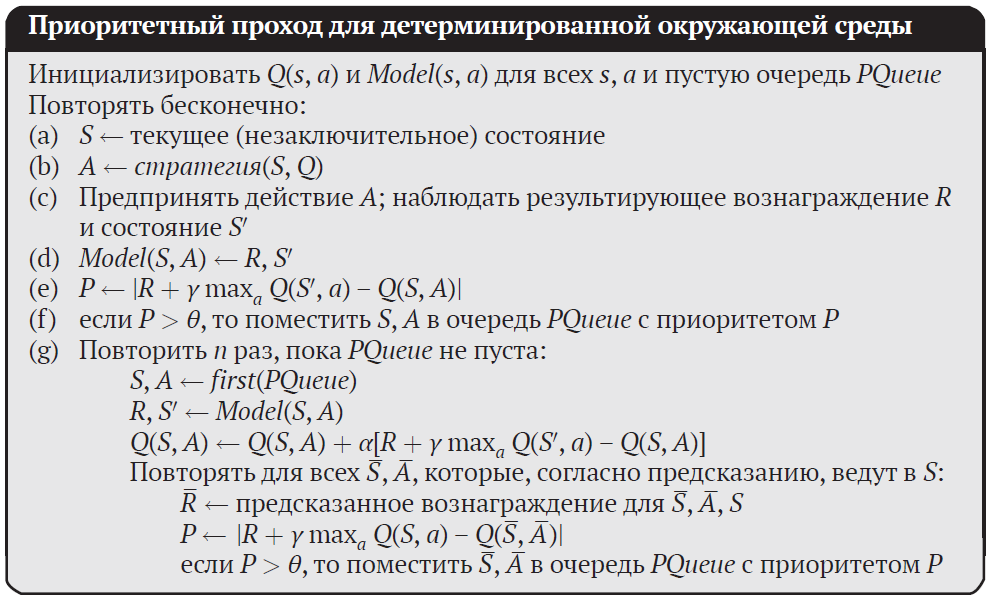

В (g) строка "Повторять для всех $\bar{S}, \bar{A}$, которые согласно предсказанию ведут в $S$" означает, что разговор о тех парах $\bar{S}, \bar{A}$, которые мы уже видели и они при этом вели в $S$.

#### Пример №4. Приоритетный проход в лабиринтах.

**<font color='orange'>Приоритетный проход значительно увеличивает скорость нахождения оптимальных решений</font>** в задачах о лабиринтах, зачастую в 5–10 раз. График показывает эту разницу в лабиринте из примера 1 с тем отличием, что **<font color='orange'>число состояний меняется</font>**.

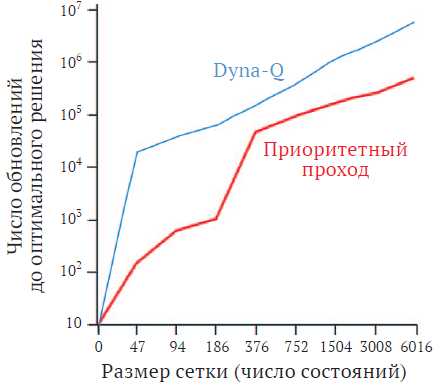

Приоритетный проход имеет безусловное преимущество над неприоритетным алгоритмом Dyna-Q. Обоим агентам потребовалось не более n = 5 обновлений за одно взаимодействие с окружающей средой.

Обобщение идеи приоритетного прохода на стохастические окружающие среды не составляет труда. Для поддержания модели в актуальном состоянии **<font color='orange'>хранятся две величины</font>**: **<font color='orange'>(1)</font>** сколько раз наблюдалась каждая пара состояние–действие и **<font color='orange'>(2)</font>** каковы при этом были следующие состояния. Далее естественно **<font color='orange'>обновлять каждую пару</font>** не выборочно, как мы делали до сих пор, а **<font color='orange'>полностью, вычисляя математическое ожидание с учетом всех возможных следующих состояний и вероятностей их возникновения</font>**.

Приоритетный проход – это лишь один из способов распределить вычисления для повышения эффективности планирования, и, пожалуй, даже не лучший. Одно из его ограничений заключается в **<font color='orange'> использовании полного обновления</font>**, что в стохастической среде может приводить к **<font color='orange'>большому объему бесполезных вычислений для маловероятных переходов</font>**.

Кроме этого, помимо обратной фокусировки можно было бы выполнять **<font color='orange'>прямую фокусировку</font>**: классифицировать состояния, исходя из того, **<font color='orange'>насколько легко их можно достичь</font>** из состояний, которые часто посещаются при текущей стратегии.

#### Обсуждение 3


1.   Проверьте на графиках из примера 2 и 3 работу приоритетного прохода в сравнении с обычным агентом Dyna-Q и Dyna-Q+.


#### Подсказки 3


1.   Берем код из предыдущих заданий и примеров №2-3, добавляем агента с приоритетным проходом.

## Сравнение выборочного и полного обновлений
>**<font color='orange'>Полное обновление</font>**, т.е. учитывающее все возможные события, или **<font color='orange'>выборочное</font>**, т.е. учитывающее только одну выборку возможных событий.

Рассмотрим на примере **<font color='orange'>одношаговых обновлений</font>**. Они различаются в основном тремя бинарными факторами.

Первые два фактора описывают, **<font color='orange'>что обновляется</font>** – ценности состояний или ценности действий, и **<font color='orange'>производится ли оценка ценности для оптимальной или для произвольно заданной стратегии</font>**. Эти два фактора определяют **<font color='orange'>четыре класса обновлений</font>** для аппроксимации четырех функций ценности: **<font color='orange'>$q^*, v^*, q_π$ и $v_π$</font>**.

Третий бинарный фактор описывает, **<font color='orange'>является ли обновление полным или выборочным</font>**. Три бинарных фактора определяют **<font color='orange'>восемь случаев, семь из которых соответствуют конкретным алгоритмам</font>**, показанным на рисунке ниже.



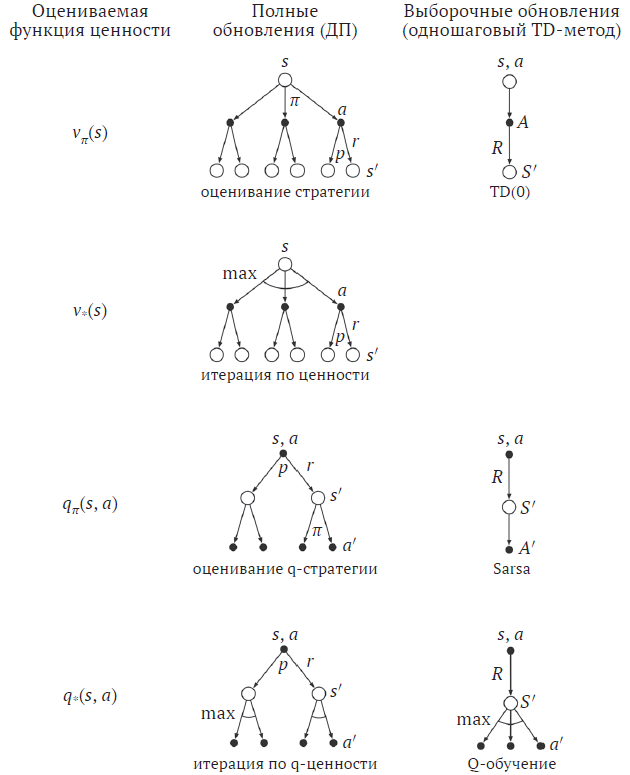

**<font color='orange'>Любое из этих одношаговых обновлений можно использовать в методах планирования.</font>** В рассмотренных выше агентах **<font color='orange'>Dyna-Q</font>**, например, используются **<font color='orange'>выборочные обновления $q^*$</font>**. Есть еще один агент - **<font color='orange'>Dyna-AC</font>**, в нем используются **<font color='orange'>выборочные обновления $v_π$</font>**  в сочетании со структурой стратегии обучения. **<font color='orange'>Для стохастических задач всегда производится приоритетный проход с использованием какого-либо вида полного обновления</font>**.

**<font color='orange'>Полные обновления</font>**, безусловно, **<font color='orange'>дают лучшие оценки</font>**, поскольку не искажаются ошибкой выборки, но они также **<font color='orange'>требуют большего объема вычислений</font>**, а вычислительные ресурсы на этапе планирования зачастую ограничены. Чтобы адекватно оценить относительные преимущества полного и выборочного обновлений применительно к планированию, необходимо учитывать **<font color='orange'>различные требования к объему вычислений</font>**.

Различие между полным и выборочным обновлениями существенно, когда **<font color='orange'>окружающая среда стохастическая</font>**. А точнее это обусловлено тем, что при заданном состоянии и действии может существовать **<font color='orange'>много следующих состояний с различными вероятностями</font>**. **<font color='orange'>Если возможно только одно следующее состояние, то полное и выборочное обновления, совпадут</font>**. Если следующих состояний может быть много, то различия могут оказаться значительными.



На рисунке ниже показаны результаты экспериментального анализа этого вопроса. Приведена **<font color='orange'>зависимость ошибки оценки от времени вычислений для полного выборочного обновления с различными коэффициентами ветвления $b$</font>**. Предполагалось, что **<font color='orange'>все $b$ состояний-преемников равновероятны</font>** и что **<font color='orange'>ошибка начальной оценки равна $1$</font>**. Предполагается также, что **<font color='orange'>ценности следующих состояний определены правильно</font>**, т.е. по завершении полного обновления ошибка уменьшается до нуля. В данном случае **<font color='orange'>выборочное обновление уменьшает ошибку по закону $\sqrt{\frac{(b – 1)}{bt}}$</font>**, где $t$ – количество произведенных выборочных обновлений (предполагается усреднение по выборке, т.е. $α = 1/t$). Ключевое наблюдение заключается в том, что **<font color='orange'>для умеренно больших $b$ ошибка очень быстро уменьшается после выполнения числа обновлений, составляющего лишь малую часть $b$</font>**. При таких обстоятельствах ценность многих пар $(s,a)$ можно было бы значительно улучшить, так что она отличалась бы от результатов полного обновления всего на несколько процентов, и для этого пришлось бы затратить столько же времени, сколько занимает полное обновление всего одной пары $(s,a)$.

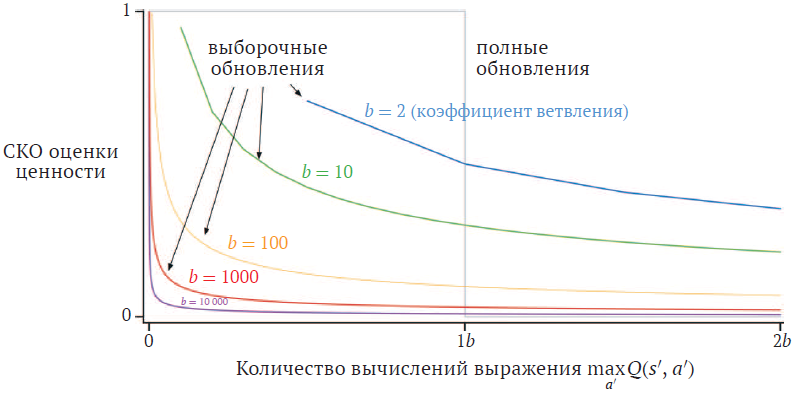

Показанное на графике преимущество в реальных условиях, возможно, будет даже более значительным. **<font color='orange'>В реальной задаче ценности состояний-преемников были бы оценками, которые сами подвергаются обновлению</font>**. Поскольку **<font color='orange'>при выборочном обновлении оценки быстрее становятся более точными</font>**, у такого способа обновления обнаруживается второе преимущество: **<font color='orange'>ценности, обновленные на основе последующих состояний, оказываются более точными</font>**. Эти результаты говорят о том, что **<font color='orange'>выборочные обновления</font>**, скорее всего, **<font color='orange'>превосходят полные в задачах с большим стохастическим коэффициентом ветвления и слишком большим числом состояний</font>**, чтобы их ценности можно было вычислить точно.

#### Обсуждение 4


1.   В приведенном выше анализе предполагалось, что все $b$ возможных следующих состояний равновероятны. Предположим вместо этого, что распределение сильно несимметрично, т. е. некоторые из $b$ состояний возникают с гораздо большей вероятностью, чем другие. При таком предположении увеличится или уменьшится преимущество выборочных обновлений над полными и почему?


#### Подсказки 4


1.   Должно увеличиваться. Почему?

## Траекторная выборка
>Два способа распределения обновлений: **<font color='orange'>исчерпывающий проход</font>** - проход по всему пространству состояний или пар $(s,a)$, и **<font color='orange'>траекторная выборка</font>** - выборка из пространства состояний или пар $(s,a)$ производится в соответствии с некоторым распределением.

Согласно классическому подходу, пришедшему **<font color='orange'>из ДП</font>**, **<font color='orange'>проход осуществляется по всему пространству состояний</font>** (или пар $(s,a)$), **<font color='orange'>при этом каждое состояние</font>** (или пара $(s,a)$) **<font color='orange'>обновляется один раз за проход</font>**. Это может вызвать проблемы при решении больших задач, потому что может **<font color='orange'>не хватить времени для завершения даже одного прохода</font>**. Кроме этого, во многих задачах подавляющее большинство состояний **<font color='orange'>не представляет никакого интереса, поскольку они посещаются только при очень плохих стратегиях или с очень низкой вероятностью</font>**. Однако, исчерпывающий проход уделяет **<font color='orange'>одинаковое время всем частям пространства состояний</font>**, вместо того чтобы сосредоточиться на тех областях, где это необходимо. Но что более предпочтительно: приоритетное планирование ближайших дня, недели, месяца или планирование случайного события, которое с некоторой вероятностью может случиться в жизни?

Согласно второму подходу, выборка из пространства состояний или пар $(s,a)$ производится **<font color='orange'>в соответствии с некоторым распределением</font>**. Можно производить **<font color='orange'>выборку из распределения с единой стратегией</font>**, т.е. из того, которое наблюдается при следовании текущей стратегии. Одним из преимуществ такого распределения является **<font color='orange'>простота его генерации</font>** - нужно лишь взаимодействовать с моделью, придерживаясь текущей стратегии. **<font color='orange'>В эпизодической задаче</font>** процесс начинается в стартовом состоянии (или в состоянии, выбираемом из распределения стартовых состояний) и далее производится имитация вплоть до заключительного состояния. **<font color='orange'>В непрерывной задаче</font>** процесс начинается в любом месте, и далее производится имитация. В обоих случаях **<font color='orange'>выборочные переходы состояний и вознаграждения определяются моделью</font>**, а **<font color='orange'>выборочные действия – текущей стратегией</font>**. Иными словами, **<font color='orange'>происходит имитация отдельных траекторий</font>** и **<font color='orange'>выполняются обновления всех встретившихся по пути состояний или пар $(s,a)$</font>**. Такой способ генерации опыта и обновлений называется **<font color='orange'>траекторной выборкой</font>**.

Является ли распределение обновлений с единой стратегией хорошим? Интуитивно кажется, что да, **<font color='orange'>по крайней мере оно лучше равномерного распределения</font>**. Например, обучаясь играть в шахматы, вы изучаете позиции, которые могут возникнуть в реальных партиях, а не случайные расстановки шахматных фигур. **<font color='orange'>Это должно значительно увеличить скорость планирования</font>**.

Использование распределения с единой стратегией может быть **<font color='orange'>выгодно</font>**, потому что при этом **<font color='orange'>игнорируются обширные области пространства состояний, не представляющих интереса</font>**. Но оно может оказаться и **<font color='orange'>вредным, поскольку приводит к многократному обновлению одних и тех же частей пространства</font>**.

#### Обсуждение 5


1.   Проверьте на графиках из примера 2 и 3 работу Dyna-Q с траекторной выборкой в сравнении с обычным агентом Dyna-Q и Dyna-Q+.


#### Подсказки 5


1.   Берем код из предыдущих заданий и примеров №2-3, добавляем модифицированного Dyna-Q с траекторной выборкой на графики.

> Единственное изменение вне планирования заключается в том, что $n$ теперь не количество шагов, а максимальная длина траектории в планировании и мы строим именно траекторию, т.о. запоминать visited_states не нужно.

> Остальное касается только палнирования. Примерный алгоритм внури привычного $for\ k\ in\ range(n)$:
> 1) начинаем с состояния $s\_sim = s$, $s$ - то состояние, которе мы видели в прямом обучении на этом шаге;
> 2) для этого состояния $s\_sim$ выбираем снова действие $a\_sim$ через $choose\_act$ (или $get\_optimal$) и проверяем, видели ли уже эту пару $(s,a)$, если нет - прекращаем планирование;
> 3) если видели, то получаем информацию из модели $Model[s\_sim[0], s\_sim[1], a\_sim]$ о награде $r\_sim$ и следующем состоянии $s\_next\_sim$, изменяем $Q[s\_sim[0], s\_sim[1], a\_sim]$.
> 4) далее меняем состояние на следующее состояние из модели $s\_sim = s\_next\_sim$ и, если следующее состояние терминальное, выходим из цикла.

## Динамическое программирование в реальном времени
>Или **<font color='orange'>ДПРВ</font>**, – это вариант алгоритма ДП с итерацией по ценности, в котором применяется **<font color='orange'>траекторная выборка с единой стратегией</font>**.

При использовании ДПРВ **<font color='orange'>ценности состояний, посещенных на фактических или имитированных траекториях, обновляются с помощью уравнения (9) в методичке 3</font>** полного табличного обновления с итерацией по ценности.

ДПРВ – пример **<font color='orange'>асинхронного алгоритма ДП</font>**. Асинхронные алгоритмы ДП строятся не на основе систематического прохода по пространству состояний, они **<font color='orange'>обновляют ценности состояний в произвольном порядке, используя уже вычисленные ценности других состояний</font>**.

В ДПРВ **<font color='orange'>порядок обновления</font>** определяется порядком, **<font color='orange'>в котором посещаются состояния на реальных или имитированных траекториях</font>**.

Если траектории могут начинаться только в выделенном множестве стартовых состояний и нас интересует задача предсказания для данной стратегии, то **<font color='orange'>траекторная выборка с единой стратегией позволяет алгоритму полностью пропускать состояния, недостижимые при следовании данной стратегии ни из одного стартового состояния</font>**; такие состояния нерелевантны задаче предсказания. В случае задачи управления, когда целью является нахождение оптимальной стратегии, а не оценивание данной стратегии, вполне могут существовать **<font color='orange'>состояния, недостижимые из стартовых ни при какой оптимальной стратегии</font>**, и для таких нерелевантных состояний совершенно необязательно описывать оптимальные действия. В действительности нам необходима оптимальная частичная стратегия, т.е. **<font color='orange'>стратегия, которая оптимальна для релевантных состояний, но может выбирать произвольные действия или даже быть вовсе неопределенной для нерелевантных</font>**.

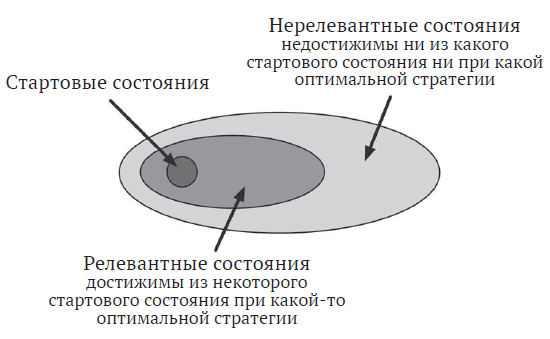

Но для нахождения оптимальной частичной стратегии требуется бесконечное число раз посетить **<font color='orange'>все пары состояние–действие, даже те, которые в итоге окажутся нерелевантными</font>**. В отличие от ситуации в задаче предсказания, вообще говоря, **<font color='orange'>невозможно прекратить обновление какого-либо состояния или пары состояние–действие, если нам важна сходимость к оптимальной стратегии</font>**.

Самый интересный результат для ДПРВ заключается в том, что **<font color='orange'>для некоторых типов задач</font>**, удовлетворяющих разумным условиям, **<font color='orange'>ДПРВ гарантированно находит стратегию, оптимальную на релевантных состояниях, не посещая каждое состояние бесконечно часто</font>**, а иногда даже не посещая некоторые состояния вовсе. Иногда такие решения нас устраивают, несмотря на то, что ранее мы боролись с проблемами непосещения каких-то состояний или состояний-действий и старались обеспечить попадание в них агента бесконечное количество раз.

В таких задачах для каждого эпизода, начинающегося в состоянии, случайно выбранном из множества стартовых состояний, и заканчивающегося в целевом состоянии, ДПРВ сходится с вероятностью 1 к стратегии, оптимальной для релевантных состояний, **<font color='orange'>при следующих условиях</font>**: **<font color='orange'>(1)</font>** начальная ценность каждого целевого состояния равна нулю; **<font color='orange'>(2)</font>** существует по крайней мере одна стратегия, гарантирующая достижимость целевого состояния с вероятностью 1 из любого стартового состояния; **<font color='orange'>(3)</font>** все вознаграждения за переходы из нецелевых состояний строго отрицательны; **<font color='orange'>(4)</font>** начальные ценности всех состояний больше или равны их оптимальным ценностям (чтобы удовлетворить этому условию, можно просто положить начальные ценности всех состояний равными нулю).

Задачи, обладающие этими свойствами, являются примерами задач **<font color='orange'>стохастической оптимизации</font>**, которые обычно формулируются в терминах **<font color='orange'>минимизации затрат</font>**, а не максимизации вознаграждения.

#### Пример №5. ДПРВ на гоночной трассе.

Вспомним задачу из методички 4 (уровень hard).

*     Поворот гоночной трассы. Гонщик хочет научится проходить повороты как можно быстрее, но при этом не вылетать с трассы. **<font color='orange'>Наложим на трассу для удобства сетку</font>**. В каждый момент времени автомобиль с гонщиком может находиться в одной из дискретных ячеек этой сетки.

  **<font color='orange'>Скорость</font>** дискретна и равна количеству ячеек, на которые машина переместилась по горизонтали и по вертикали за один временной шаг. **<font color='orange'>Действиями</font>** в задаче будут приращения составляющих скорости в промежутке $[-1; 1]$ с шагом $1$ (т.к. направления у скорости два, то **<font color='orange'>действий всего будет девять $(3*3)$</font>**). **<font color='orange'>Награда</font>** за каждый шаг $R = -1$.
  
  **<font color='orange'>Обе составляющие скорости должны быть неотрицательны и меньше 5, и одновременно могут быть равны 0 только на линии старта.</font>**
  
  Каждый **<font color='orange'>эпизод</font>** начинается в одном из случайно выбранных **<font color='orange'>начальных состояний</font>** (скорость $= (0,0)$), а заканчивается, когда машина пересечет **<font color='orange'>линию финиша</font>**. **<font color='orange'>Если машина задела границу трассы, то она возвращается в случайную позицию на линии старта</font>** со скоростью $= (0,0)$, **<font color='orange'>и эпизод продолжается</font>**. Прежде чем обновлять положение машины на каждом шаге, следует **<font color='orange'>проверить, не вылетела ли она за пределы трассы</font>**.

Эта задача является **<font color='orange'>задачей стохастической оптимизации</font>**. Сравнение ДПРВ с традиционным алгоритмом ДП методом итерации по ценности в этой задаче иллюстрирует некоторые преимущества траекторной выборки с единой стратегией.

Единственное изменение: **<font color='orange'>в этом варианте задачи нет ограничения на скорость машины</font>**, поэтому **<font color='orange'>множество состояний потенциально бесконечно</font>**. Однако **<font color='orange'>множество состояний, достижимых из множества стартовых состояний при любой стратегии, конечно</font>** и может рассматриваться как пространство состояний задачи.

Как и раньше:
* каждый эпизод начинается в случайно выбранном стартовом состоянии и завершается, когда машина пересечет финишную черту;
* за каждый шаг, предшествующий пересечению финишной черты, начисляется вознаграждение $–1$;
* если машина задевает границу трассы, она возвращается в случайное стартовое состояние, и эпизод продолжается.


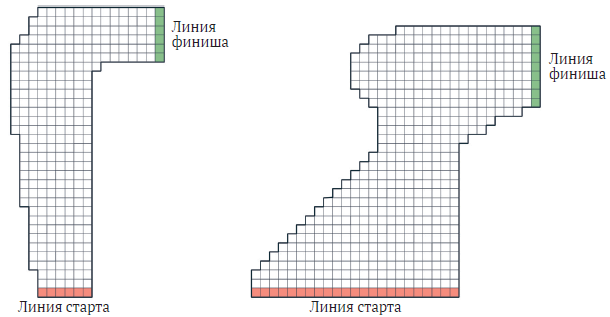

Гоночная трасса, изображенная в левой части, имеет **<font color='orange'> 9115 состояний, достижимых из стартовых состояний при какой-либо стратегии</font>**, но из них только **<font color='orange'>599 релевантны</font>**, т.е. достижимы из какого-либо стартового состояния при какой-то оптимальной стратегии (для оценки количества релевантных состояний подсчитывались состояния, посещенные при выборе оптимальных действий в $10^7$ эпизодах).



В таблице ниже сравниваются решения этой задачи методами традиционного ДП и ДПРВ. **<font color='orange'>Результаты усреднены по 25 запускам</font>**, каждый из которых случайно генерировался **<font color='orange'>с новым начальным значением</font>**.

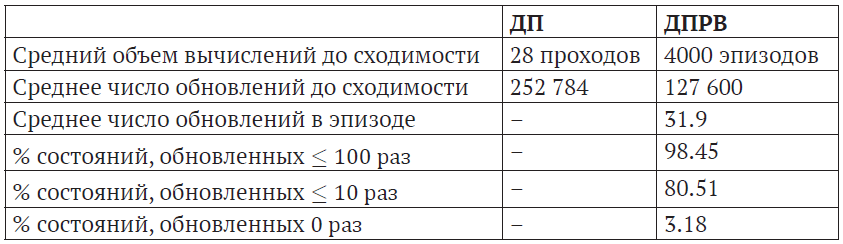

Методом традиционного ДП в данном случае являлась **<font color='orange'>итерация по ценности с применением исчерпывающего прохода по множеству состояний</font>**, при этом **<font color='orange'>состояния обновлялись на месте по одному за раз</font>**, т.е. при обновлении каждого состояния использовались самые актуальные ценности других состояний. Порядок обновлений специально не выбирался; возможно, при другом порядке сходимость была бы быстрее. В каждом прогоне обоих методов **<font color='orange'>начальные ценности были равны нулю</font>**. Считалось, что **<font color='orange'>ДП сошелся, когда максимальное изменение ценности состояний после прохода было меньше $10^{–4}$</font>**, а **<font color='orange'>ДПРВ – когда время до пересечения финишной черты, усредненное по $20$ эпизодам, выраженное в количестве шагов, стабилизировалось</font>**. В этом варианте ДПРВ на каждом шаге обновлялась только ценность текущего состояния.

Оба метода выработали стратегии, требующие в среднем **<font color='orange'>от 14 до 15 шагов для пересечения финишной черты</font>**, но **<font color='orange'>в случае ДПРВ понадобилось почти вдвое меньше обновлений</font>**, чем в случае ДП. Это результат траекторной выборки с единой стратегией, примененной в ДПРВ.

**<font color='orange'>Еще одно преимущество ДПРВ</font>** состоит в том, что **<font color='orange'>когда функция ценности стремится к оптимальной функции ценности $v*$, стратегия</font>**, применяемая агентом для генерации траекторий, **<font color='orange'>стремится к оптимальной стратегии</font>**, поскольку она всегда является жадной относительно текущей функции ценности (напомним, что оптимальные стратегии могут быть жадными относительно многих разных функций ценности, а не только $v^*$). **<font color='orange'>В традиционном алгоритме ДП не проверяется, является ли оптимальной стратегия, выработанная до сходимости итерации по ценности</font>**, такая проверка потребовала бы **<font color='orange'>большого объема дополнительных вычислений</font>**.

## Что еще осталось по планированию на следующий раз?

* Планирование в момент принятия решений и эвристический поиск.
* Разыгрывающие алгоритмы.
* Поиск по дереву методом МК.